In [1]:
import pathlib
import numpy as np
import scipy as sp
from astropy.io import fits
import matplotlib.pyplot as plt


In [2]:
here = pathlib.Path('.')
calibration_image = "ubai2505m"


In [3]:
def get_file_list(file_type, calibration_image):
    file_list = sorted(
    f for f in here.rglob("*" + file_type + "*.fits")
    if f.name.startswith(calibration_image))
    return file_list

def read_fits_data(file_list):
    data_list = []
    for file in file_list:
        with fits.open(file) as hdul:
            hdu = next((h for h in hdul if h.data is not None), None)
            if hdu is None:
                raise ValueError(f"No image data found in {file}")
            data_list.append(hdu.data.copy())
    return data_list
# Extend this so it creates a calibration_image dictionary where each key is a file_type for the same source image

In [4]:
raw_files = get_file_list("raw", calibration_image)
mask_files = get_file_list("maskfile", calibration_image)

In [5]:
mask_files

[WindowsPath('hst-data/calibration/ubai2505m/ubai2505m_maskfile.fits')]

In [6]:
a = read_fits_data(raw_files)
b = read_fits_data(mask_files)
a

[array([[[300, 300, 300, ..., 300, 299, 300],
         [301, 300, 300, ..., 300, 300, 300],
         [303, 300, 300, ..., 300, 301, 300],
         ...,
         [300, 300, 300, ..., 301, 304, 313],
         [301, 300, 300, ..., 301, 303, 306],
         [301, 300, 300, ..., 301, 300, 301]],
 
        [[334, 321, 320, ..., 320, 320, 320],
         [351, 326, 332, ..., 320, 320, 320],
         [485, 366, 379, ..., 320, 320, 320],
         ...,
         [321, 320, 320, ..., 321, 320, 320],
         [321, 320, 320, ..., 320, 320, 320],
         [322, 320, 320, ..., 320, 320, 321]],
 
        [[320, 314, 314, ..., 314, 313, 315],
         [323, 313, 314, ..., 313, 314, 314],
         [325, 314, 314, ..., 315, 314, 314],
         ...,
         [314, 314, 314, ..., 314, 314, 314],
         [314, 314, 314, ..., 313, 313, 314],
         [313, 314, 313, ..., 314, 314, 314]],
 
        [[300, 299, 298, ..., 299, 299, 299],
         [298, 299, 300, ..., 299, 299, 300],
         [299, 299, 300, ...,

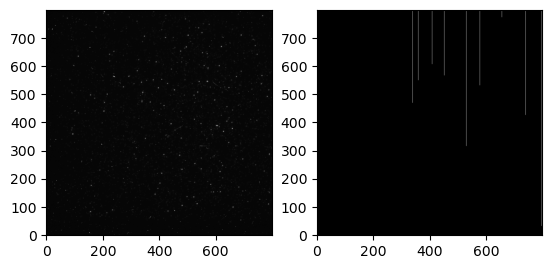

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(a[0][0], origin='lower', cmap='gray', vmax=a[0][0].mean() * 2)
ax2.imshow(b[0][0], origin='lower', cmap='gray')
plt.show()

In [ ]:
# Next step, apply the mask to the raw file. Replace deffective pixels (2) with a NaN and check if questionable pixels (256) align with anything. 
# Save the result